# КТ4 · Может ли сеть ускорить согласование карты?
Сеть получает шесть чисел из текущей итерации КТ3 и предлагает положительное демпфирование λ. Каждый шаг проходит общую проверку убывания функции потерь. Данные разделены по целым маршрутам. Модели обучаются на CPU, сохраняются на диск и снова загружаются перед испытанием.

**Гипотеза.** Память может сократить число решений на маршрутах с пропусками VO. Сравнение включает адаптивный классический LM, постоянное начальное демпфирование, MLP, локальную RNN и ту же RNN с отключённой памятью.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path
from threadpoolctl import threadpool_limits
name='kt4_work'
work=Path.cwd() if Path.cwd().name==name else Path.cwd()/name
work.mkdir(exist_ok=True)
os.chdir(work)
sys.path.insert(0,str(work))
Path('slam_lab').mkdir(exist_ok=True)
threadpool_limits(limits=1)
print('Рабочая папка',work)

Рабочая папка /tmp/slam-course-rispdzd_/tuned4/kt4_work


### Библиотека плоского SLAM
Первая поза закреплена. Относительное движение задано в осях начальной позы каждого интервала. Дальности и координаты выражены в метрах, углы в радианах. Генератор возвращает наблюдения и эталон разными объектами. Функция `solve(graph)` получает только граф измерений.

In [2]:
%%writefile slam_lab/graph.py
"""Planar factor graph. Coordinates are metres, angles radians, gyro bias rad/s."""
from dataclasses import dataclass
import numpy as np


def wrap(a):
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi


def rotate(v, angle):
    x, y = np.moveaxis(np.asarray(v), -1, 0)
    c, s = np.cos(angle), np.sin(angle)
    return np.stack((c*x - s*y, s*x + c*y), axis=-1)


def relative(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.r_[rotate(b[:2] - a[:2], -a[2]), wrap(b[2] - a[2])]


def compose(a, step):
    a, step = np.asarray(a), np.asarray(step)
    return np.r_[a[:2] + rotate(step[:2], a[2]), wrap(a[2] + step[2])]


@dataclass(frozen=True)
class Factor:
    kind: str
    i: int
    j: int
    z: tuple
    sigma: tuple
    dt: float = 1.


@dataclass(frozen=True)
class Graph:
    poses: int
    landmarks: int
    factors: tuple


SIZES = {'wheel': 3, 'vo': 3, 'loop': 3, 'gyro': 1, 'beacon': 2}


def validate(graph):
    if not isinstance(graph.poses, (int, np.integer)) or graph.poses < 2:
        raise ValueError('poses must be an integer >= 2')
    if not isinstance(graph.landmarks, (int, np.integer)) or graph.landmarks < 0:
        raise ValueError('landmark count must be a nonnegative integer')
    for k, f in enumerate(graph.factors):
        limit = graph.landmarks if f.kind == 'beacon' else graph.poses
        indices = all(isinstance(v, (int, np.integer)) for v in (f.i, f.j))
        dim = SIZES.get(f.kind, 0)
        if not dim or not indices or not (0 <= f.i < graph.poses and 0 <= f.j < limit):
            raise ValueError(f'factor {k}: invalid kind or index')
        if f.kind != 'beacon' and f.i == f.j:
            raise ValueError(f'factor {k}: identical pose indices')
        z, sigma = np.asarray(f.z, float), np.asarray(f.sigma, float)
        if z.shape != (dim,) or sigma.shape != (dim,) or not np.isfinite(np.r_[z, sigma]).all() or np.any(sigma <= 0):
            raise ValueError(f'factor {k}: invalid value, dimension or sigma')
        if (f.kind == 'beacon' and z[0] <= 0) or (f.kind == 'gyro' and (not np.isfinite(f.dt) or f.dt <= 0)):
            raise ValueError(f'factor {k}: invalid range or gyro interval')


def wheel_path(graph):
    steps = {f.i: f.z for f in graph.factors if f.kind == 'wheel' and f.j == f.i + 1}
    if len(steps) != graph.poses-1:
        raise ValueError('initialization requires a continuous wheel chain')
    p = np.zeros((graph.poses, 3))
    for i in range(graph.poses-1):
        p[i+1] = compose(p[i], steps[i])
    return p


class Problem:
    """Compile the measurement graph once. No reference poses or landmark map are accepted."""
    def __init__(self, graph):
        validate(graph)
        self.graph = graph
        self.dim = 3*(graph.poses-1) + 2*graph.landmarks + 1
        self.groups = []
        self.blocks = []
        start = 0
        for kind, width in SIZES.items():
            items = [f for f in graph.factors if f.kind == kind]
            if not items:
                continue
            end = start + len(items)*width
            rows = np.arange(start, end).reshape(-1, width)
            self.groups.append((kind, rows, np.array([f.i for f in items]), np.array([f.j for f in items]),
                                np.array([f.z for f in items]), np.array([f.sigma for f in items]),
                                np.array([f.dt for f in items])))
            self.blocks.extend([width] * len(items))
            start = end
        self.rows = start
        self.starts = np.cumsum([0]+self.blocks[:-1])

    def initial(self):
        poses = wheel_path(self.graph)
        samples = [[] for _ in range(self.graph.landmarks)]
        for f in self.graph.factors:
            if f.kind == 'beacon':
                d, a = f.z
                samples[f.j].append(poses[f.i,:2] + rotate([d, 0.], a + poses[f.i,2]))
        if any(not s for s in samples):
            raise ValueError('unobserved landmark')
        landmarks = np.array([np.median(s, axis=0) for s in samples])
        return np.r_[poses[1:].ravel(), landmarks.ravel(), 0.]

    def unpack(self, x):
        split = 3*(self.graph.poses-1)
        return np.r_[np.zeros(3), x[:split]].reshape(-1,3), x[split:-1].reshape(-1,2), x[-1]

    def linearize(self, x, jac=True):
        poses, marks, bias = self.unpack(x)
        residual = np.empty(self.rows)
        # Work with absolute pose column numbers, then drop the three anchored columns.
        J = np.zeros((self.rows, self.dim+3)) if jac else None
        for kind, rows, i, j, z, sigma, dt in self.groups:
            ri = rows[:,0]
            ca, sa = np.cos(poses[i,2]), np.sin(poses[i,2])
            if kind in ('vo','wheel','loop'):
                body = rotate(poses[j,:2]-poses[i,:2], -poses[i,2])
                err = np.column_stack((body-z[:,:2], wrap(poses[j,2]-poses[i,2]-z[:,2])))
                if jac:
                    rj, rk = rows[:,1], rows[:,2]
                    J[ri,3*j], J[ri,3*j+1], J[rj,3*j], J[rj,3*j+1] = ca, sa, -sa, ca
                    J[ri,3*i], J[ri,3*i+1], J[rj,3*i], J[rj,3*i+1] = -ca, -sa, sa, -ca
                    J[ri,3*i+2], J[rj,3*i+2] = body[:,1], -body[:,0]
                    J[rk,3*i+2], J[rk,3*j+2] = -1., 1.
            elif kind == 'gyro':
                err = wrap(poses[j,2]-poses[i,2]+bias*dt-z[:,0])[:,None]
                if jac:
                    J[ri,3*i+2], J[ri,3*j+2], J[ri,-1] = -1., 1., dt
            else:
                dx, dy = (marks[j]-poses[i,:2]).T
                dist = np.hypot(dx,dy)
                if np.any(dist < 1e-8):
                    raise ValueError('undefined bearing at zero distance')
                err = np.column_stack((dist-z[:,0], wrap(np.arctan2(dy,dx)-poses[i,2]-z[:,1])))
                if jac:
                    col = 3*self.graph.poses+2*j
                    rb = rows[:,1]
                    J[ri,col], J[ri,col+1] = dx/dist, dy/dist
                    J[rb,col], J[rb,col+1] = -dy/dist**2, dx/dist**2
                    J[ri,3*i], J[ri,3*i+1] = -dx/dist, -dy/dist
                    J[rb,3*i], J[rb,3*i+1], J[rb,3*i+2] = dy/dist**2, -dx/dist**2, -1.
            residual[rows] = err/sigma
            if jac:
                J[rows] /= sigma[:,:,None]
        return residual, (J[:,3:] if jac else None)

    def loss(self, r, delta):
        # Huber is applied to the norm of a whole normalized sensor block.
        squared = np.add.reduceat(r*r, self.starts)
        if delta is None:
            return .5 * squared.sum(), np.ones_like(squared)
        if not np.isfinite(delta) or delta <= 0:
            raise ValueError('Huber threshold must be positive')
        lengths = np.sqrt(squared)
        weights = np.minimum(1., delta/np.maximum(lengths, 1e-30))
        cost = np.where(lengths <= delta, .5*squared, delta*(lengths-.5*delta))
        return cost.sum(), weights

    def objective(self, x, delta):
        return self.loss(self.linearize(x, jac=False)[0], delta)[0]


Writing slam_lab/graph.py


In [3]:
%%writefile slam_lab/solver.py
"""Damped Gauss–Newton with one acceptance rule for all damping policies."""
from dataclasses import dataclass
import time
import numpy as np
from .graph import Problem

MIN_LAMBDA, MAX_LAMBDA = 1e-7, 1e5


@dataclass
class Iteration:
    r: np.ndarray
    H: np.ndarray
    g: np.ndarray
    diag: np.ndarray
    cost: float
    features: np.ndarray


def linear_step(problem, x, delta, previous_lambda, rho):
    r, J = problem.linearize(x)
    cost, weights = problem.loss(r, delta)
    weighted = J * np.repeat(weights, problem.blocks)[:,None]
    H, g = weighted.T @ J, weighted.T @ r
    diag = np.maximum(np.diag(H), 1e-8)
    features = np.array([np.log10(1+np.linalg.norm(g,np.inf)), np.log10(1+np.linalg.norm(r)),
                         np.log10(diag.max()/diag.min()), np.mean(weights < 1.),
                         np.log10(previous_lambda), np.clip(rho,-2.,2.)])
    return Iteration(r,H,g,diag,float(cost),features)


def trial(problem, x, state, damping, delta):
    A = state.H.copy()
    A.flat[::len(x)+1] += damping * state.diag
    try:
        dx = np.linalg.solve(A, -state.g)
        candidate = x + dx
        cost = problem.objective(candidate, delta)
        predicted = -state.g@dx - .5*dx@state.H@dx
    except (ValueError, np.linalg.LinAlgError, FloatingPointError):
        return x, np.inf, 0.
    ratio = (state.cost-cost)/predicted if predicted > 0 else 0.
    return candidate, float(cost), float(ratio)


@dataclass
class Estimate:
    x: np.ndarray
    poses: np.ndarray
    landmarks: np.ndarray
    bias: float
    history: list
    solves: int
    rejects: int
    status: str
    seconds: float


def solve(graph, *, delta=2.5, policy='classical', initial_lambda=.003, iterations=24,
          budget=48, x0=None):
    """policy is 'classical', 'fixed', or an object implementing reset() and propose(features)."""
    if not MIN_LAMBDA <= initial_lambda <= MAX_LAMBDA or budget < 1 or iterations < 1:
        raise ValueError('invalid damping or solve budget')
    if isinstance(policy,str) and policy not in ('classical','fixed'):
        raise ValueError('unknown damping policy')
    started = time.perf_counter()
    pb = Problem(graph)
    x = pb.initial() if x0 is None else np.asarray(x0,dtype=float).copy()
    if x.shape != (pb.dim,) or not np.isfinite(x).all():
        raise ValueError('invalid initial state')
    if not isinstance(policy,str):
        policy.reset()
    previous = current = float(initial_lambda)
    rho = 1.
    history = [float(pb.objective(x, delta))]
    solves = rejects = 0
    status = 'iteration_limit'
    for _ in range(iterations):
        state = linear_step(pb, x, delta, previous, rho)
        if np.linalg.norm(state.g, np.inf) < 1e-7:
            status = 'small_gradient'
            break
        if isinstance(policy,str):
            damping = initial_lambda if policy == 'fixed' else current
        else:
            proposal = float(policy.propose(state.features.copy()))
            damping = np.clip(proposal, MIN_LAMBDA, MAX_LAMBDA) if np.isfinite(proposal) and proposal > 0 else current
        accepted = False
        for _attempt in range(8):
            candidate, cost, new_rho = trial(pb,x,state,damping,delta)
            solves += 1
            if np.isfinite(cost) and cost < state.cost:
                x = candidate
                history.append(cost)
                previous, rho = damping, new_rho
                factor = .35 if rho > .75 else (2. if rho < .25 else 1.)
                current = float(np.clip(damping*factor, MIN_LAMBDA, MAX_LAMBDA))
                accepted = True
                break
            rejects += 1
            if solves == budget or damping >= MAX_LAMBDA:
                break
            damping = min(MAX_LAMBDA, 10*damping)
        if not accepted:
            status = 'budget' if solves >= budget else 'no_descent'
            break
        if state.cost-cost <= 1e-8*(1+state.cost):
            status = 'small_decrease'
            break
        if solves >= budget:
            status = 'budget'
            break
    poses, marks, bias = pb.unpack(x)
    return Estimate(x,poses,marks,float(bias),history,solves,rejects,status,time.perf_counter()-started)


Writing slam_lab/solver.py


In [4]:
%%writefile slam_lab/bench.py
"""Synthetic observations, kept apart from the truth used for scoring."""
from dataclasses import dataclass
import numpy as np
from .graph import Factor, Graph, relative, rotate, wrap


@dataclass(frozen=True)
class Reference:
    poses: np.ndarray
    landmarks: np.ndarray
    bias: float


def episode(seed, condition='outliers', length=21):
    if condition not in ('clean','outliers','dropout','false_loop','transfer'):
        raise ValueError('unknown episode condition')
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 2*np.pi, length)
    a, b = rng.uniform(1.7,2.4), rng.uniform(1.,1.5)
    if condition == 'transfer':
        b *= .55
    xy = np.column_stack((a*np.sin(t), b*(1-np.cos(t))))
    yaw = np.arctan2(b*np.sin(t), a*np.cos(t))
    poses = np.column_stack((xy,yaw))
    marks = np.array([[-3.4,.4],[-1.3,4.2],[1.8,4.5],[3.6,.7],[.3,-1.7]]) + rng.normal(0,.15,(5,2))
    bias = rng.uniform(.025,.065)
    factors = []
    def add(kind,i,j,z,sigma):
        factors.append(Factor(kind,i,j,tuple(z),tuple(sigma)))
    for i,p in enumerate(poses):
        if i < length-1:
            rel = relative(p, poses[i+1])
            wheel = rel + rng.normal(0,[.040,.018,.021]) + [.045 + .075*(i%9 < 3),0,.012]
            add('wheel',i,i+1,wheel,[.09,.04,.05])
            visual = rel + rng.normal(0,[.035,.035,.025])
            if rng.random() > .13 and not (condition == 'dropout' and length//4 <= i < 3*length//4):
                add('vo',i,i+1,visual,[.035,.035,.025])
            add('gyro',i,i+1,[wrap(rel[2]+bias+rng.normal(0,.012))],[.012])
        for j in (i % 5,(i+2)%5):
            d = marks[j]-p[:2]
            measure = [np.linalg.norm(d)+rng.normal(0,.065), wrap(np.arctan2(d[1],d[0])-p[2]+rng.normal(0,.028))]
            if condition != 'clean' and (3*i+j)%17 == 0:
                measure[0] += 1.5
                measure[1] = wrap(measure[1]-.43)
            add('beacon',i,j,measure,[.065,.028])
    loop = relative(poses[0],poses[-1]) + rng.normal(0,[.045,.045,.02])
    if condition == 'false_loop':
        loop += [1.6,-.9,.45]
    add('loop',0,length-1,loop,[.055,.055,.025])
    return Graph(length,len(marks),tuple(factors)), Reference(poses,marks,bias)


def score(poses, truth, landmarks=None):
    xy_error = poses[:,:2]-truth.poses[:,:2]
    est = rotate(np.diff(poses[:,:2],axis=0), -poses[:-1,2])
    ref = rotate(np.diff(truth.poses[:,:2],axis=0), -truth.poses[:-1,2])
    def rmse(vec):
        return float(np.sqrt(np.mean(np.sum(vec**2,axis=1))))
    return {'ate_m':rmse(xy_error), 'rpe_m':rmse(est-ref),
            'map_m':rmse(landmarks-truth.landmarks) if landmarks is not None else float('nan')}


Writing slam_lab/bench.py


In [5]:
%%writefile slam_lab/__init__.py
from .graph import Factor, Graph, Problem, compose, relative, validate, wheel_path, wrap
from .solver import Estimate, solve


Writing slam_lab/__init__.py


### Обучение и общий тест
Учитель перебирает восемь значений λ и из вариантов с уменьшением не меньше 95% лучшего выбирает наибольшее λ. Признаки описывают градиент, невязку, разброс диагонали H, долю ослабленных факторов и предыдущий шаг. Нормировка оценивается на обучающих маршрутах. Для каждой сети сравниваются 3 ширины и 3 шага Adam. Выбор весов, ширины и эпохи определяется MSE на валидации; тестовые маршруты 1810–1817 открываются после выбора.

In [6]:
%%writefile damping_advisor.py
"""Small trainable damping policies for the guarded solver in slam_lab."""
from pathlib import Path
import numpy as np
from slam_lab.solver import linear_step, trial
from slam_lab import Problem

# Six observable diagnostics in the order returned by slam_lab.solver.linear_step.
FEATURES = ('log_gradient','log_residual','log_diagonal_ratio','downweighted','last_log_lambda','last_rho')
GRID = np.logspace(-5,1,8)


def teacher_sequence(graph, delta=2.5):
    """Labels use objective reduction only. Resolve near-ties towards the safer damping."""
    pb = Problem(graph)
    x = pb.initial()
    previous, rho = .003, 1.
    features, labels = [], []
    for _ in range(12):
        state=linear_step(pb,x,delta,previous,rho)
        attempts=[trial(pb,x,state,lam,delta) for lam in GRID]
        drops=np.array([state.cost-cost for _,cost,_ in attempts])
        if drops.max() <= 1e-8*(1+state.cost):
            break
        chosen=np.flatnonzero(drops >= .95*drops.max())[-1]
        previous=float(GRID[chosen])
        x,_,rho=attempts[chosen]
        features.append(state.features)
        labels.append(np.log10(previous))
    return np.array(features),np.array(labels)


class DampingAdvisor:
    """A tanh MLP or diagonal recurrent layer, followed by bounded log10(lambda)."""
    def __init__(self,width=12,recurrent=False,cap=.8,seed=19):
        if not (width>=1 and 0<=cap<1):
            raise ValueError('invalid width or memory cap')
        rng=np.random.default_rng(seed)
        self.recurrent,self.cap=recurrent,float(cap)
        self.params={'W':rng.normal(0,.27,(len(FEATURES),width)),'b':np.zeros(width),
                     'v':rng.normal(0,.13,width),'c':np.zeros(1),'u':np.full(width,min(.22, cap) if recurrent else 0.)}
        self.center,self.scale=np.zeros(len(FEATURES)),np.ones(len(FEATURES))
        self.reset()

    def reset(self):
        self.hidden=np.zeros_like(self.params['b'])

    def advance(self, x, previous):
        p=self.params
        return np.tanh(x@p['W']+p['b']+p['u']*previous)

    def forward(self, features):
        x=(np.asarray(features)-self.center)/self.scale
        h=np.zeros((len(x)+1,len(self.hidden)))
        for k,row in enumerate(x):
            h[k+1]=self.advance(row,h[k])
        a=np.tanh(h[1:]@self.params['v']+self.params['c'][0])
        return x,h,a

    def propose(self,features):
        x=(features-self.center)/self.scale
        self.hidden=self.advance(x,self.hidden)
        out=np.tanh(self.hidden@self.params['v']+self.params['c'][0])
        return float(10**(-2.+3.*out))

    def loss(self,sequences):
        err=[(-2+3*self.forward(X)[2]-y)**2 for X,y in sequences]
        return float(np.mean(np.concatenate(err)))

    def fit(self,training,validation,epochs=65,lr=.014):
        X=np.concatenate([x for x,_ in training])
        self.center=X.mean(0)
        self.scale=np.maximum(X.std(0),.05)
        p=self.params
        m={k:np.zeros_like(v) for k,v in p.items()}
        v={k:np.zeros_like(q) for k,q in p.items()}
        n=sum(len(y) for _,y in training)
        history=[]
        best=None
        for epoch in range(1,epochs+1):
            grad={k:np.zeros_like(w) for k,w in p.items()}
            for observed,target in training:
                x,h,a=self.forward(observed)
                # Backpropagate log-damping MSE through the bounded readout and through time.
                do=(2/n)*(-2+3*a-target)*3*(1-a*a)
                grad['v']+=h[1:].T@do
                grad['c'][0]+=do.sum()
                carry=np.zeros_like(self.hidden)
                for k in reversed(range(len(x))):
                    dz=(p['v']*do[k]+carry)*(1-h[k+1]**2)
                    grad['W']+=np.outer(x[k],dz)
                    grad['b']+=dz
                    if self.recurrent:
                        grad['u']+=h[k]*dz
                    carry=p['u']*dz
            for key in p:
                m[key]=.9*m[key]+.1*grad[key]
                v[key]=.999*v[key]+.001*grad[key]**2
                p[key]-=lr*(m[key]/(1-.9**epoch))/(np.sqrt(v[key]/(1-.999**epoch))+1e-8)
            p['u'][:]=np.clip(p['u'],-self.cap,self.cap) if self.recurrent else 0.
            val=self.loss(validation)
            history.append((epoch,self.loss(training),val))
            if best is None or val<best[0]:
                best=(val,{k:w.copy() for k,w in p.items()})
        self.params=best[1]
        self.reset()
        return np.array(history)

    def save(self,path):
        np.savez(Path(path),**self.params,center=self.center,scale=self.scale,cap=self.cap,
                 recurrent=self.recurrent,features=np.array(FEATURES))

    @classmethod
    def load(cls,path):
        with np.load(path,allow_pickle=False) as data:
            if tuple(data['features'])!=FEATURES:
                raise ValueError('incompatible feature order')
            model=cls(len(data['b']),bool(data['recurrent']),float(data['cap']))
            for key,template in model.params.items():
                a=data[key]
                if a.shape!=template.shape or not np.isfinite(a).all():
                    raise ValueError(f'invalid parameter: {key}')
                model.params[key]=a.copy()
            model.center,model.scale=data['center'].copy(),data['scale'].copy()
            if (model.scale.shape!=(len(FEATURES),) or model.center.shape!=model.scale.shape
                    or not np.isfinite(np.r_[model.center,model.scale]).all() or np.any(model.scale<=0)
                    or np.max(np.abs(model.params['u']))>model.cap
                    or (not model.recurrent and np.any(model.params['u']))):
                raise ValueError('incompatible scaling or memory')
        model.reset()
        return model


Writing damping_advisor.py


In [7]:
%%writefile study_neuro.py
"""Train by imitating offline LM trials and compare policies on held-out routes."""
from pathlib import Path
import json
import platform
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

# Local checkout with the companion KT3 library, or the installed gallery-fusion-slam package.
sibling=Path(__file__).resolve().parents[1]/'КТ3'
if sibling.is_dir():
    sys.path.insert(0,str(sibling))

from slam_lab import solve
from slam_lab.bench import episode, score
from damping_advisor import DampingAdvisor, GRID, teacher_sequence

TRAIN=tuple(range(310,330))
VALID=tuple(range(710,716))
TEST=tuple(range(1810,1818))
WIDTHS=(8,12,16)
RATES=(.006,.014,.025)
SCENARIOS=('clean','outliers','dropout','false_loop')
BUDGET=24


def sequences(seeds):
    return [teacher_sequence(episode(seed,SCENARIOS[k%len(SCENARIOS)])[0]) for k,seed in enumerate(seeds)]


def tune_classical():
    rows=[]
    for lam in (.0003,.003,.03):
        for k,seed in enumerate(VALID):
            graph,_=episode(seed,SCENARIOS[k%4])
            sol=solve(graph,budget=BUDGET,initial_lambda=lam)
            rows.append(dict(initial_lambda=lam,seed=seed,solves=sol.solves,cost=sol.history[-1],status=sol.status))
    val=pd.DataFrame(rows)
    med=val.groupby('initial_lambda').solves.mean()
    return float(med.idxmin()),val


def select_model(name, train, valid):
    """Select weights, epoch and architecture without running the held-out SLAM tests."""
    candidates=[]
    best_key=None
    for width in WIDTHS:
        for lr in RATES:
            model=DampingAdvisor(width=width,recurrent=name=='rnn',cap=.8,seed=19)
            trace=model.fit(train,valid,epochs=65,lr=lr)
            epoch=int(np.argmin(trace[:,2]))
            mse=float(trace[epoch,2])
            row=dict(model=name,width=width,lr=lr,best_epoch=epoch+1,train_mse=float(trace[epoch,1]),
                     validation_mse=mse,max_abs_u=float(np.max(abs(model.params['u']))))
            candidates.append(row)
            # If validation MSE ties, prefer a narrower layer, then a smaller learning rate.
            key=(mse,width,lr)
            if best_key is None or key<best_key:
                best_key=key
                chosen,chosen_trace,chosen_row=model,trace,row
    for row in candidates:
        row['selected']=row is chosen_row
    return chosen,chosen_trace,chosen_row,candidates


def run(folder='results'):
    folder=Path(folder);folder.mkdir(exist_ok=True,parents=True)
    records=[];history=[];selection=[];chosen={}
    with threadpool_limits(limits=1):
        train,valid=sequences(TRAIN),sequences(VALID)
        lam,baselines=tune_classical()
        baselines.to_csv(folder/'classical_validation.csv',index=False)
        policies={'classical':'classical','fixed':'fixed'}
        for name in ('mlp','rnn'):
            model,h,choice,candidates=select_model(name,train,valid)
            chosen[name]=choice
            selection.extend(candidates)
            model.save(folder/(name+'.npz'))
            policies[name]=DampingAdvisor.load(folder/(name+'.npz'))
            history.extend(dict(model=name,epoch=int(e),train=a,validation=b) for e,a,b in h)
        pd.DataFrame(selection).to_csv(folder/'selection.csv',index=False)
        ablated=DampingAdvisor.load(folder/'rnn.npz')
        ablated.params['u'][:]=0.
        policies['rnn_u0']=ablated
        for scenario in (*SCENARIOS,'transfer'):
            for seed in TEST:
                graph,ref=episode(seed,scenario)
                for name,policy in policies.items():
                    sol=solve(graph,policy=policy,initial_lambda=lam,budget=BUDGET)
                    assert np.all(np.diff(sol.history)<0)
                    records.append(dict(seed=seed,scenario=scenario,policy=name,**score(sol.poses,ref,sol.landmarks),
                          cost=sol.history[-1],solves=sol.solves,rejects=sol.rejects,status=sol.status,
                          elapsed_ms=1000*sol.seconds,accepted=len(sol.history)-1))
    df=pd.DataFrame(records); hist=pd.DataFrame(history)
    df.to_csv(folder/'runs.csv',index=False);hist.to_csv(folder/'learning.csv',index=False)
    summary=df.groupby(['scenario','policy'])[['ate_m','rpe_m','map_m','cost','solves','rejects','elapsed_ms']].mean()
    summary.to_csv(folder/'summary.csv')
    protocol=dict(train=TRAIN,validation=VALID,test=TEST,training_steps=sum(len(y) for _,y in train),
                  validation_steps=sum(len(y) for _,y in valid),teacher_grid=GRID.tolist(),
                  width_grid=WIDTHS,learning_rate_grid=RATES,selection_metric='minimum validation log-damping MSE',
                  selected=chosen,cap=.8,epochs=65,budget=BUDGET,initial_lambda=lam,
                  model_seed=19,numpy=np.__version__,python=platform.python_version())
    (folder/'protocol.json').write_text(json.dumps(protocol,indent=2))
    fig,ax=plt.subplots(1,2,figsize=(10,3.8),layout='constrained')
    for name,color in [('mlp','#b56931'),('rnn','#007b80')]:
        sub=hist[hist.model==name]
        ax[0].plot(sub.epoch,sub.train,ls=':',color=color,label=name.upper()+' · train')
        ax[0].plot(sub.epoch,sub.validation,color=color,label=name.upper()+' · val')
    ax[0].set(xlabel='Эпоха',ylabel='MSE по log₁₀ λ',title='Обучение советника');ax[0].legend(fontsize=8)
    means=df.groupby('policy',sort=False).solves.mean()
    for ix,(method,m) in enumerate(means.items()):
        ax[1].bar(ix,m,color=['#546e7a','#adb8be','#b56931','#007b80','#81b7b4'][ix])
    ax[1].set(xticks=range(len(means)),xticklabels=means.index,ylabel='Линейных решений на запуск',title='40 отложенных сценариев')
    fig.savefig(folder/'learning_and_cost.png',dpi=150);plt.close(fig)
    return summary


if __name__=='__main__':
    print(run().round(4).to_string())


Writing study_neuro.py


,model,width,lr,best_epoch,validation_mse
4,mlp,12,0.014,9,0.184669
12,rnn,12,0.006,19,0.202397


ate_m   rpe_m  solves  rejects
scenario   policy                                    
clean      classical  0.0482  0.0349   5.375      0.0
           fixed      0.0482  0.0349   5.375      0.0
           mlp        0.0482  0.0349   7.375      0.0
           rnn        0.0482  0.0349   7.375      0.0
           rnn_u0     0.0482  0.0349   7.750      0.0
dropout    classical  0.0755  0.0498   6.125      0.0
           fixed      0.0755  0.0498   6.125      0.0
           mlp        0.0755  0.0498   7.250      0.0
           rnn        0.0755  0.0498   6.750      0.0
           rnn_u0     0.0755  0.0498   7.250      0.0
false_loop classical  0.0621  0.0397   7.250      0.0
           fixed      0.0621  0.0397   7.500      0.0
           mlp        0.0621  0.0397   8.250      0.0
           rnn        0.0621  0.0397   8.250      0.0
           rnn_u0     0.0621  0.0397   8.250      0.0
outliers   classical  0.0705  0.0382   6.000      0.0
           fixed      0.0705  0.0382   6.000      0.0
           mlp        0.0705  0.0382   6.625      0.0
           rnn        0.0705  0.0382   6.250      0.0
           rnn_u0     0.0705  0.0382   6.500      0.0
transfer   classical  0.0714  0.0376   6.000      0.0
           fixed      0.0714  0.0376   6.000      0.0
           mlp        0.0714  0.0376   6.875      0.0
           rnn        0.0714  0.0376   6.500      0.0
           rnn_u0     0.0714  0.0376   6.500      0.0

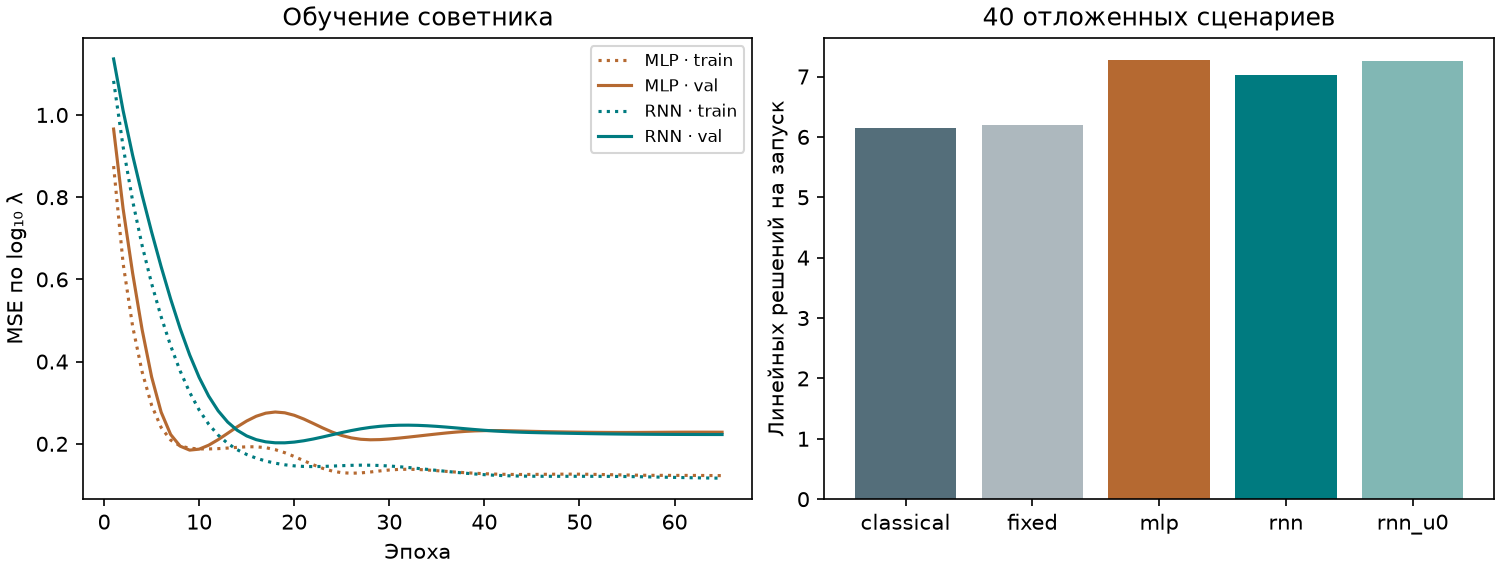

In [8]:
from study_neuro import run, sequences, TRAIN, VALID, TEST, DampingAdvisor, episode, solve, score
from IPython.display import Image, display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
table=run('results')
choices=pd.read_csv('results/selection.csv')
display(choices[choices.selected][['model','width','lr','best_epoch','validation_mse']])
display(table[['ate_m','rpe_m','solves','rejects']].round(4))
display(Image(filename='results/learning_and_cost.png'))

### Панель обучения
Выберите архитектуру, ширину сети, темп обучения и ограничение рекуррентной связи. Справа сравниваются две различные начальные памяти при одинаковых последующих входах. Кнопка запуска пересчитывает графики на train и validation.

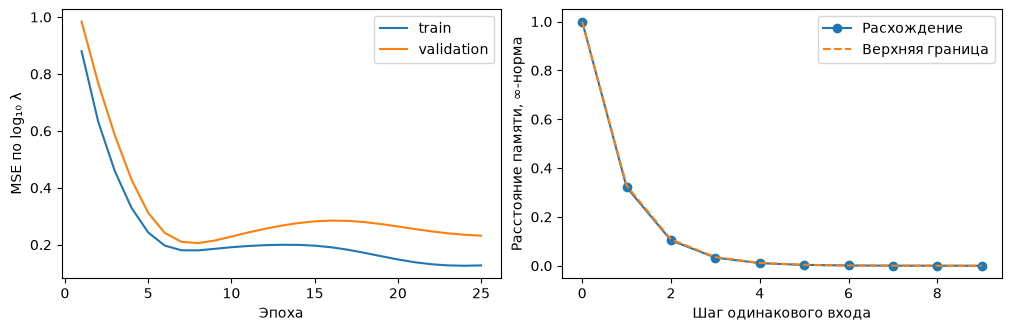

interactive(children=(Dropdown(description='network', index=1, options=('mlp', 'rnn'), value='rnn'), IntSlider…

In [9]:
import ipywidgets as w
from functools import lru_cache
@lru_cache(maxsize=1)
def training_data():
    return sequences(TRAIN),sequences(VALID)
def training_panel(network='rnn',width=12,lr=.014,epochs=25,cap=.8):
    train,val=training_data()
    model=DampingAdvisor(width=width,recurrent=network=='rnn',cap=cap)
    trace=model.fit(train,val,epochs,lr)
    fig,ax=plt.subplots(1,2,figsize=(10,3.2),layout='constrained')
    ax[0].plot(trace[:,0],trace[:,1],label='train')
    ax[0].plot(trace[:,0],trace[:,2],label='validation')
    ax[0].set(xlabel='Эпоха',ylabel='MSE по log₁₀ λ');ax[0].legend()
    h1,h2=np.ones(width),np.zeros(width); norms=[]
    for step in range(10):
        norms.append(np.max(np.abs(h1-h2)))
        h1=model.advance(np.zeros(6),h1);h2=model.advance(np.zeros(6),h2)
    ax[1].plot(norms,'o-',label='Расхождение')
    ax[1].plot(np.max(abs(model.params['u']))**np.arange(10),'--',label='Верхняя граница')
    ax[1].set(xlabel='Шаг одинакового входа',ylabel='Расстояние памяти, ∞-норма');ax[1].legend()
    plt.show()
training_panel()
train_controls=w.interactive(training_panel,{'manual':True,'manual_name':'Обучить'},
    network=['mlp','rnn'],width=(4,24,2),lr=(.002,.03,.002),epochs=(10,80,5),cap=(0.,.9,.05))
display(train_controls)

### Панель испытания
Меняются seed, метод, начальное демпфирование, порог Хьюбера и бюджет. Этот запуск использует сохранённые веса. Истина доступна функции оценки после завершения итераций.

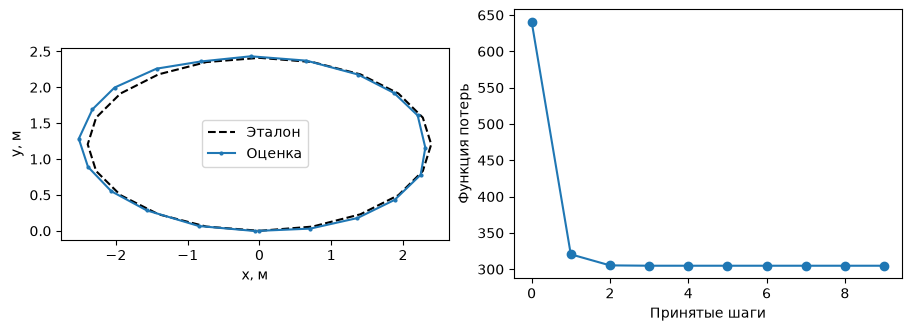

ATE, м 0.0987 | решений 9 | отказов 0 | остановка small_decrease


interactive(children=(IntSlider(value=1810, description='seed', max=2000, min=1800), Dropdown(description='sce…

In [10]:
def trial_panel(seed=1810,scenario='dropout',method='rnn',use_huber=True,
                log_start=-3.,budget=24):
    graph,ref=episode(seed,scenario)
    policy=DampingAdvisor.load('results/'+method+'.npz') if method in ('mlp','rnn') else method
    estimate=solve(graph,policy=policy,delta=2.5 if use_huber else None,
                   initial_lambda=10**log_start,budget=budget)
    fig,ax=plt.subplots(1,2,figsize=(9,3.2),layout='constrained')
    ax[0].plot(*ref.poses[:,:2].T,'k--',label='Эталон')
    ax[0].plot(*estimate.poses[:,:2].T,'o-',ms=2,label='Оценка')
    ax[0].set(aspect='equal',xlabel='x, м',ylabel='y, м');ax[0].legend()
    ax[1].plot(estimate.history,'o-');ax[1].set(xlabel='Принятые шаги',ylabel='Функция потерь')
    plt.show()
    print('ATE, м',round(score(estimate.poses,ref)['ate_m'],4),'| решений',estimate.solves,
          '| отказов',estimate.rejects,'| остановка',estimate.status)
trial_panel()
run_controls=w.interactive(trial_panel,{'manual':True,'manual_name':'Пересчитать'},
    seed=(1800,2000),scenario=['clean','outliers','dropout','false_loop','transfer'],
    method=['classical','fixed','mlp','rnn'],use_huber=True,log_start=(-6.,1.,.5),budget=(1,40))
display(run_controls)

### Отказ шага и граница применимости
Последний тест с плохим начальным приближением и бюджетом одного решения проверяет сохранность текущей оценки после отклонения предложения. Между маршрутами скрытая память обнуляется. Контракт сжатия |uᵢ| < 1 относится к памяти при общем входе.

In [11]:
%%writefile test_advisor.py
import tempfile
import unittest
from pathlib import Path
import numpy as np
from study_neuro import DampingAdvisor, episode, solve, TRAIN, VALID, TEST
from slam_lab import Problem


class AdvisorChecks(unittest.TestCase):
    def test_feature_input_and_reset(self):
        class Probe:
            def reset(self):
                self.seen=[]
            def propose(self, values):
                assert values.shape==(6,) and np.isfinite(values).all()
                self.seen.append(values)
                return .002
        graph,_=episode(410)
        probe=Probe()
        first=solve(graph,policy=probe)
        n=len(probe.seen)
        again=solve(graph,policy=probe)
        self.assertEqual(len(probe.seen),n)
        np.testing.assert_array_equal(first.x,again.x)
        self.assertTrue(np.all(np.diff(first.history)<0))

    def test_contraction_and_roundtrip(self):
        net=DampingAdvisor(9,recurrent=True,cap=.75)
        x=np.linspace(-1.,1.,6)
        a,b=np.ones(9),-np.ones(9)
        diff=np.max(np.abs(net.advance(x,a)-net.advance(x,b)))
        self.assertLessEqual(diff,np.max(abs(net.params['u']))*np.max(abs(a-b)))
        net.reset();ref=[net.propose(x),net.propose(x)]
        with tempfile.TemporaryDirectory() as d:
            ckpt=Path(d)/'test.npz';net.save(ckpt)
            other=DampingAdvisor.load(ckpt)
            np.testing.assert_allclose(ref,[other.propose(x),other.propose(x)],atol=1e-14)
        self.assertTrue(all(1e-5<=v<=10 for v in ref))

    def test_invalid_proposal_and_guard(self):
        class Broken:
            def reset(self): pass
            def propose(self, x): return np.nan
        g,_=episode(412)
        sol=solve(g,policy=Broken())
        self.assertTrue(np.all(np.diff(sol.history)<0))
        g,_=episode(1620,'false_loop')
        pb=Problem(g)
        x=pb.initial()+np.random.default_rng(2).normal(0,3,pb.dim)
        refused=solve(g,policy='fixed',initial_lambda=1e-7,x0=x,budget=1)
        self.assertEqual((refused.status,refused.rejects,refused.solves),('budget',1,1))
        np.testing.assert_array_equal(refused.x,x)

    def test_route_split(self):
        self.assertFalse(set(TRAIN)&set(VALID) or set(TRAIN)&set(TEST) or set(VALID)&set(TEST))


if __name__=='__main__':
    unittest.main()


Writing test_advisor.py


In [12]:
import subprocess, sys
check = subprocess.run([sys.executable,'-m','unittest','-v','test_advisor'], capture_output=True,text=True)
print(check.stderr)
check.check_returncode()

test_contraction_and_roundtrip (test_advisor.AdvisorChecks.test_contraction_and_roundtrip) ... ok
test_feature_input_and_reset (test_advisor.AdvisorChecks.test_feature_input_and_reset) ... ok
test_invalid_proposal_and_guard (test_advisor.AdvisorChecks.test_invalid_proposal_and_guard) ... ok
test_route_split (test_advisor.AdvisorChecks.test_route_split) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.044s

OK



### Вывод
На 40 тестовых сочетаниях маршрута и сценария классическому LM понадобилось в среднем 6,150 линейного решения, MLP — 7,275, RNN — 7,025. Валидация выбрала 12 скрытых единиц у обеих сетей, шаг Adam 0,014 для MLP и 0,006 для RNN. Бюджет и критерий принятия у методов общие. Сохранённые сети пригодны для повторения опыта; для этого стенда выбираю классическое правило.